In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# Configuration
np.random.seed(42)
n_samples = 100

# Di sini, kita akan coba menggenerate data linear sintetis
X = np.linspace(0, 10, n_samples).reshape(-1, 1)
y = 2 * X.ravel() + 1 + np.random.randn(n_samples) * 2

In [6]:
X[:10]

array([[0.        ],
       [0.1010101 ],
       [0.2020202 ],
       [0.3030303 ],
       [0.4040404 ],
       [0.50505051],
       [0.60606061],
       [0.70707071],
       [0.80808081],
       [0.90909091]])

In [8]:
y[:10]

array([1.99342831, 0.9254916 , 2.69941748, 4.65212032, 1.33977406,
       1.5418271 , 5.37054684, 3.94901087, 1.67721284, 3.90330191])

**Data Generation**

In [10]:
# Configuration
np.random.seed(42)
n_samples = 100

# Di sini, kita akan coba menggenerate data linear sintetis
X = np.linspace(0, 10, n_samples).reshape(-1, 1)
y = 2 * X.ravel() + 1 + np.random.randn(n_samples) * 2

In [11]:
X[:10]

array([[0.        ],
       [0.1010101 ],
       [0.2020202 ],
       [0.3030303 ],
       [0.4040404 ],
       [0.50505051],
       [0.60606061],
       [0.70707071],
       [0.80808081],
       [0.90909091]])

In [12]:
y[:10]

array([1.99342831, 0.9254916 , 2.69941748, 4.65212032, 1.33977406,
       1.5418271 , 5.37054684, 3.94901087, 1.67721284, 3.90330191])

**Data Splitting**


In [14]:
# Split data: 70% Train, 30% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

**Model Training & Validation**

## Training Sederhana

In [15]:
# Inisialisasi model
model = LinearRegression()

# Kita akan coba dengan training sederhana terlebih dahulu
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Hitung metrics evaluasinya
mse_holdout = mean_squared_error(y_test, y_pred)
r2_holdout = r2_score(y_test, y_pred)

print(f"--- Hold-out Evaluation (30% Test) ---")
print(f"Test MSE: {mse_holdout:.2f}")
print(f"Test R2:  {r2_holdout:.2f}\n")

--- Hold-out Evaluation (30% Test) ---
Test MSE: 2.22
Test R2:  0.94



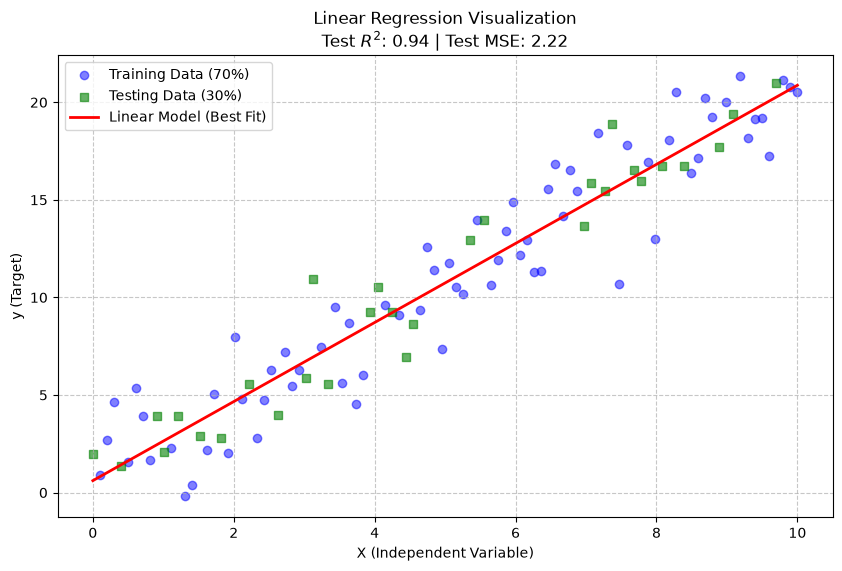

In [16]:
# Buat range untuk semua titik yang ada dalam data
X_range = np.linspace(0, 10, 100).reshape(-1, 1)
y_range_pred = model.predict(X_range)

plt.figure(figsize=(10, 6))

# Plot Training Data
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Training Data (70%)')

# Plot Testing Data
plt.scatter(X_test, y_test, color='green', alpha=0.6, label='Testing Data (30%)', marker='s')

# Plot Regression linenya
plt.plot(X_range, y_range_pred, color='red', linewidth=2, label='Linear Model (Best Fit)')

# Tampilkan
plt.title(f"Linear Regression Visualization\nTest $R^2$: {r2_holdout:.2f} | Test MSE: {mse_holdout:.2f}")
plt.xlabel("X (Independent Variable)")
plt.ylabel("y (Target)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

**K-fold Cross Validation**

Cross-Validation (CV) adalah teknik evaluasi yang lebih kuat (robust). Alih-alih hanya membagi data satu kali, kita membagi data menjadi $K$ bagian (disebut folds).

Cara Kerja K-Fold (Misal $K=5$):

1. Data dibagi menjadi 5 bagian yang sama besar.
2. Iterasi 1: Bagian 1 jadi data uji, sisanya (2,3,4,5) jadi data latih.
3. Iterasi 2: Bagian 2 jadi data uji, sisanya jadi data latih.
4. Proses ini diulang sampai semua bagian pernah menjadi data uji.
5. Hasil akhir adalah rata-rata dari skor di setiap iterasi.

In [17]:
# 5-Fold Cross Validation
# Kita akan menggunakan dataset utuh (X, y) karena cross_val_score
# akan melakukan splitting secara mandiri
model = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2_scores = cross_val_score(model, X, y, cv=kf, scoring='r2')
cv_mse_scores = -cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')

print(f"--- 5-Fold Cross-Validation ---")
print(f"Mean CV R2:   {cv_r2_scores.mean():.4f} ± {cv_r2_scores.std():.4f}")
print(f"Mean CV MSE:  {cv_mse_scores.mean():.2f} ± {cv_mse_scores.std():.2f}")

--- 5-Fold Cross-Validation ---
Mean CV R2:   0.9018 ± 0.0325
Mean CV MSE:  3.32 ± 1.43


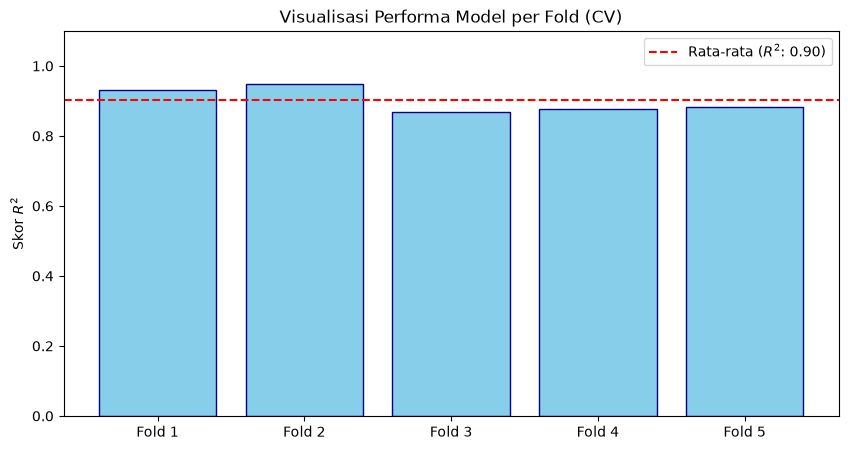

In [18]:
# Visualisasi Hasil Cross Validation
plt.figure(figsize=(10, 5))
folds = [f"Fold {i+1}" for i in range(len(cv_r2_scores))]
plt.bar(folds, cv_r2_scores, color='skyblue', edgecolor='navy')
plt.axhline(y=cv_r2_scores.mean(), color='red', linestyle='--', label=f'Rata-rata ($R^2$: {cv_r2_scores.mean():.2f})')

plt.title("Visualisasi Performa Model per Fold (CV)")
plt.ylabel("Skor $R^2$")
plt.ylim(0, 1.1)
plt.legend()
plt.show()